In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import classification_report

from sklearn.ensemble import BaggingClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

from imblearn.under_sampling import NearMiss
from imblearn.over_sampling import RandomOverSampler

from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier

import warnings
warnings.filterwarnings("ignore")
pd.options.display.max_rows = 100
pd.options.display.max_columns = 100

In [2]:
data=pd.read_csv('../input/company-bankruptcy-prediction/data.csv')
df=data.copy()
df.head()

,Bankrupt?,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,Continuous interest rate (after tax),Operating Expense Rate,Research and development expense rate,Cash flow rate,Interest-bearing debt interest rate,Tax rate (A),Net Value Per Share (B),Net Value Per Share (A),Net Value Per Share (C),Persistent EPS in the Last Four Seasons,Cash Flow Per Share,Revenue Per Share (Yuan ¥),Operating Profit Per Share (Yuan ¥),Per Share Net profit before tax (Yuan ¥),Realized Sales Gross Profit Growth Rate,Operating Profit Growth Rate,After-tax Net Profit Growth Rate,Regular Net Profit Growth Rate,Continuous Net Profit Growth Rate,Total Asset Growth Rate,Net Value Growth Rate,Total Asset Return Growth Rate Ratio,Cash Reinvestment %,Current Ratio,Quick Ratio,Interest Expense Ratio,Total debt/Total net worth,Debt ratio %,Net worth/Assets,Long-term fund suitability ratio (A),Borrowing dependency,Contingent liabilities/Net worth,Operating profit/Paid-in capital,Net profit before tax/Paid-in capital,Inventory and accounts receivable/Net value,Total Asset Turnover,Accounts Receivable Turnover,Average Collection Days,Inventory Turnover Rate (times),Fixed Assets Turnover Frequency,Net Worth Turnover Rate (times),Revenue per person,Operating profit per person,Allocation rate per person,Working Capital to Total Assets,Quick Assets/Total Assets,Current Assets/Total Assets,Cash/Total Assets,Quick Assets/Current Liability,Cash/Current Liability,Current Liability to Assets,Operating Funds to Liability,Inventory/Working Capital,Inventory/Current Liability,Current Liabilities/Liability,Working Capital/Equity,Current Liabilities/Equity,Long-term Liability to Current Assets,Retained Earnings to Total Assets,Total income/Total expense,Total expense/Assets,Current Asset Turnover Rate,Quick Asset Turnover Rate,Working capitcal Turnover Rate,Cash Turnover Rate,Cash Flow to Sales,Fixed Assets to Assets,Current Liability to Liability,Current Liability to Equity,Equity to Long-term Liability,Cash Flow to Total Assets,Cash Flow to Liability,CFO to Assets,Cash Flow to Equity,Current Liability to Current Assets,Liability-Assets Flag,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,0.780985,1.256969e-04,0.0,0.458143,0.000725,0.0,0.147950,0.147950,0.147950,0.169141,0.311664,0.017560,0.095921,0.138736,0.022102,0.848195,0.688979,0.688979,0.217535,4.980000e+09,0.000327,0.263100,0.363725,0.002259,0.001208,0.629951,0.021266,0.207576,0.792424,0.005024,0.390284,0.006479,0.095885,0.137757,0.398036,0.086957,0.001814,0.003487,1.820926e-04,1.165007e-04,0.032903,0.034164,0.392913,0.037135,0.672775,0.166673,0.190643,0.004094,0.001997,1.473360e-04,0.147308,0.334015,0.276920,0.001036,0.676269,0.721275,0.339077,0.025592,0.903225,0.002022,0.064856,7.010000e+08,6.550000e+09,0.593831,4.580000e+08,0.671568,0.424206,0.676269,0.339077,0.126549,0.637555,0.458609,0.520382,0.312905,0.118250,0,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,0.781506,2.897851e-04,0.0,0.461867,0.000647,0.0,0.182251,0.182251,0.182251,0.208944,0.318137,0.021144,0.093722,0.169918,0.022080,0.848088,0.689693,0.689702,0.217620,6.110000e+09,0.000443,0.264516,0.376709,0.006016,0.004039,0.635172,0.012502,0.171176,0.828824,0.005059,0.376760,0.005835,0.093743,0.168962,0.397725,0.064468,0.001286,0.004917,9.360000e+09,7.190000e+08,0.025484,0.0068

In [3]:
df.shape

(6819, 96)

In [4]:
df.columns= [i.lower().strip().replace(' ', '_') for i in df.columns]
df.columns

Index(['bankrupt?', 'roa(c)_before_interest_and_depreciation_before_interest',
       'roa(a)_before_interest_and_%_after_tax',
       'roa(b)_before_interest_and_depreciation_after_tax',
       'operating_gross_margin', 'realized_sales_gross_margin',
       'operating_profit_rate', 'pre-tax_net_interest_rate',
       'after-tax_net_interest_rate',
       'non-industry_income_and_expenditure/revenue',
       'continuous_interest_rate_(after_tax)', 'operating_expense_rate',
       'research_and_development_expense_rate', 'cash_flow_rate',
       'interest-bearing_debt_interest_rate', 'tax_rate_(a)',
       'net_value_per_share_(b)', 'net_value_per_share_(a)',
       'net_value_per_share_(c)', 'persistent_eps_in_the_last_four_seasons',
       'cash_flow_per_share', 'revenue_per_share_(yuan_¥)',
       'operating_profit_per_share_(yuan_¥)',
       'per_share_net_profit_before_tax_(yuan_¥)',
       'realized_sales_gross_profit_growth_rate',
       'operating_profit_growth_rate', 'after-tax

In [5]:
df.shape

(6819, 96)

## checking the missing values

In [6]:
df.isnull().sum().sum()

0

## checking dublicate values

In [7]:
df.duplicated().sum()

0

# Exploratory Data Analysis

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                   Non-Null Count  Dtype  
---  ------                                                   --------------  -----  
 0   bankrupt?                                                6819 non-null   int64  
 1   roa(c)_before_interest_and_depreciation_before_interest  6819 non-null   float64
 2   roa(a)_before_interest_and_%_after_tax                   6819 non-null   float64
 3   roa(b)_before_interest_and_depreciation_after_tax        6819 non-null   float64
 4   operating_gross_margin                                   6819 non-null   float64
 5   realized_sales_gross_margin                              6819 non-null   float64
 6   operating_profit_rate                                    6819 non-null   float64
 7   pre-tax_net_interest_rate                                6819 non-null   float64
 8   after-tax_net_interest_rate 

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
bankrupt?,6819.0,3.226280e-02,1.767102e-01,0.0,0.000000e+00,0.000000e+00,0.000000e+00,1.000000e+00
roa(c)_before_interest_and_depreciation_before_interest,6819.0,5.051796e-01,6.068564e-02,0.0,4.765271e-01,5.027056e-01,5.355628e-01,1.000000e+00
roa(a)_before_interest_and_%_after_tax,6819.0,5.586249e-01,6.562003e-02,0.0,5.355430e-01,5.598016e-01,5.891572e-01,1.000000e+00
roa(b)_before_interest_and_depreciation_after_tax,6819.0,5.535887e-01,6.159481e-02,0.0,5.272766e-01,5.522780e-01,5.841051e-01,1.000000e+00
operating_gross_margin,6819.0,6.079480e-01,1.693381e-02,0.0,6.004447e-01,6.059975e-01,6.139142e-01,1.000000e+00
realized_sales_gross_margin,6819.0,6.079295e-01,1.691607e-02,0.0,6.004338e-01,6.059759e-01,6.138421e-01,1.000000e+00
operating_profit_rate,6819.0,9.987551e-01,1.301003e-02,0.0,9.989692e-01,9.990222e-01,9.990945e-01,1.000000e+00
pre-tax_net_interest_rate,6819.0,7.971898e-01,1.286899e-02,0.0,7.973859e-01,7.974636e-01,7.975788e-01,1.000000e+00
after-tax_net_interest_rate,6819.0,8.090836e-01,1.360065e-02,0.0,8.093116e-01,8.093752e-01,8.094693e-01,1.000000e+00
non-industry_income_and_expenditure/revenue,6819.0,3.036229e-01,1.116344e-02,0.0,3.034663e-01,3.035255e-01,3.035852e-01,1.000000e+00


In [10]:
#let us check the Target variable
df['bankrupt?'].value_counts()

0    6599
1     220
Name: bankrupt?, dtype: int64

Text(0.5, 1.0, 'Bankrupt')

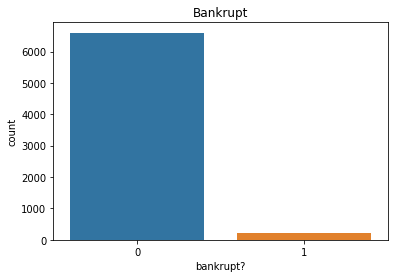

In [11]:
sns.countplot(x=df['bankrupt?'])
plt.title('Bankrupt')

In [12]:
df['liability-assets_flag'].value_counts()

0    6811
1       8
Name: liability-assets_flag, dtype: int64

Text(0.5, 1.0, 'Liability assets flag')

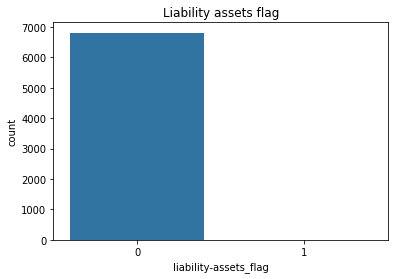

In [13]:
sns.countplot(x=df['liability-assets_flag'])
plt.title('Liability assets flag')

In [14]:
df['net_income_flag'].value_counts()

1    6819
Name: net_income_flag, dtype: int64

Text(0.5, 1.0, 'net_income_flag')

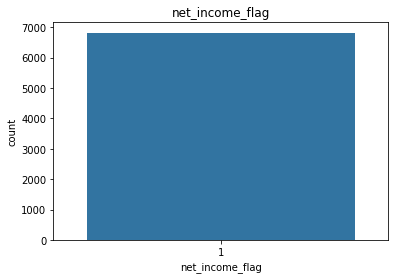

In [15]:
sns.countplot(x=df['net_income_flag'])
plt.title('net_income_flag')

In [16]:
df.drop('net_income_flag', axis=1, inplace=True)

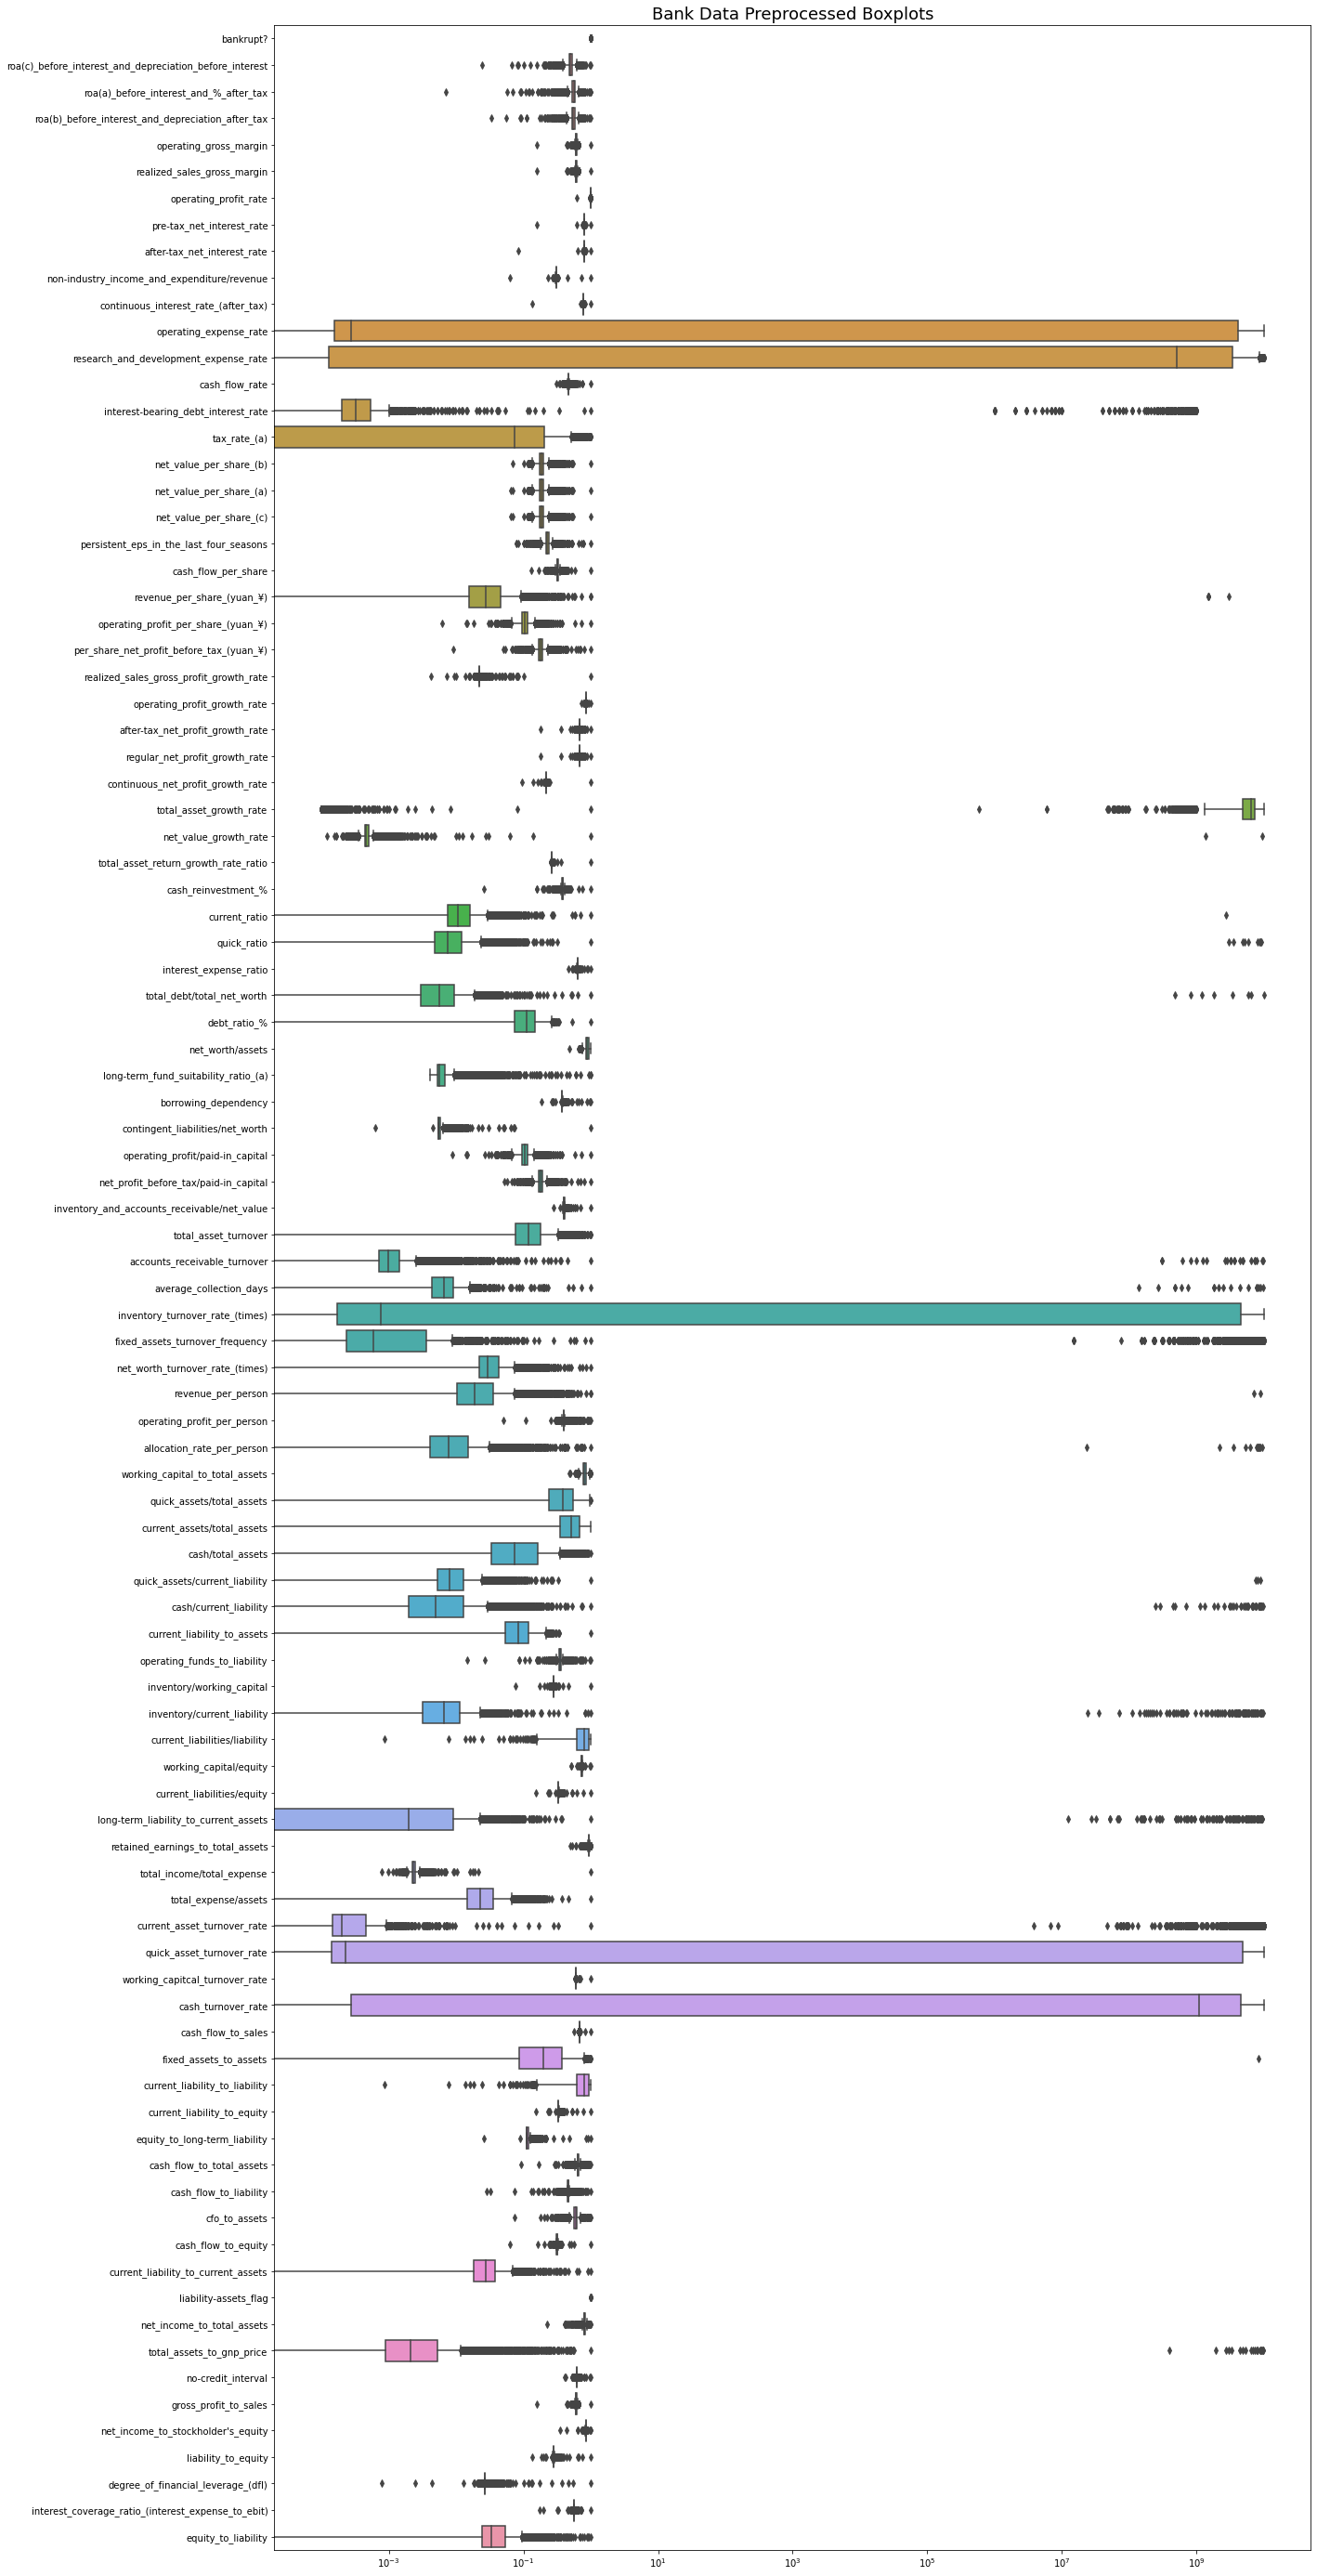

In [17]:
plt.figure(figsize = (20,50))
ax =sns.boxplot(data = df, orient="h")
ax.set_title('Bank Data Preprocessed Boxplots', fontsize = 18)
ax.set(xscale="log")
plt.show()

In [18]:
X = df.iloc[:,1:]
Y = df.iloc[:,[0]]
scaler = RobustScaler()
X.iloc[:,:] = scaler.fit_transform(X)

In [19]:
x_train, x_test, y_train, y_test = train_test_split(X, Y , test_size=0.3, random_state=42, stratify=Y)

## Bagging Classifier

In [20]:
svm = SVC(probability=True)

bag = BaggingClassifier(base_estimator= svm, n_estimators = 10, max_samples = 0.4, max_features = 35,
                 bootstrap = True, bootstrap_features = True, n_jobs = -1, random_state = 123)

In [21]:
bag.fit(x_train, y_train)
bag_pred = bag.predict(x_test)

In [22]:
print(classification_report(y_test,bag_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1980
           1       0.00      0.00      0.00        66

    accuracy                           0.97      2046
   macro avg       0.48      0.50      0.49      2046
weighted avg       0.94      0.97      0.95      2046



In [23]:
classifier=RandomForestClassifier()

bag_us = BaggingClassifier(base_estimator= classifier, n_estimators = 10, max_samples = 0.4, max_features = 35,random_state = 123)

In [24]:
bag.fit(x_train, y_train)
bag_pred = bag.predict(x_test)

In [25]:
print(classification_report(y_test,bag_pred))

              precision    recall  f1-score   support

           0       0.97      1.00      0.98      1980
           1       0.00      0.00      0.00        66

    accuracy                           0.97      2046
   macro avg       0.48      0.50      0.49      2046
weighted avg       0.94      0.97      0.95      2046



# Inbalance problem

## Undersampling

In [26]:
undersample = NearMiss(version=1, n_neighbors=3)
x_train_us, y_train_us = undersample.fit_resample(x_train, y_train)

In [27]:
y_train_us.value_counts()

bankrupt?
0            154
1            154
dtype: int64

## Bagging Classifier

In [28]:
classifier=RandomForestClassifier()

bag_us = BaggingClassifier(base_estimator= classifier, n_estimators = 10, max_samples = 0.4, max_features = 35,random_state = 123)

bag_us.fit(x_train_us, y_train_us)

BaggingClassifier(base_estimator=RandomForestClassifier(), max_features=35,
                  max_samples=0.4, random_state=123)

In [29]:
bag_pred = bag_us.predict(x_test)
print(classification_report(y_test,bag_pred))

              precision    recall  f1-score   support

           0       1.00      0.67      0.80      1980
           1       0.09      0.92      0.16        66

    accuracy                           0.68      2046
   macro avg       0.54      0.80      0.48      2046
weighted avg       0.97      0.68      0.78      2046



## Boosting models

In [30]:
gbc = GradientBoostingClassifier(random_state = 0)
gbc.fit(x_train_us, y_train_us)
gbc_pred = gbc.predict(x_test)

In [31]:
print(classification_report(y_test,gbc_pred))

              precision    recall  f1-score   support

           0       1.00      0.59      0.74      1980
           1       0.07      0.98      0.14        66

    accuracy                           0.60      2046
   macro avg       0.54      0.79      0.44      2046
weighted avg       0.97      0.60      0.72      2046



In [32]:
xgbt = XGBClassifier()
xgbt.fit(x_train_us, y_train_us)
xgb_pred = xgbt.predict(x_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       1.00      0.60      0.75      1980
           1       0.08      0.98      0.14        66

    accuracy                           0.61      2046
   macro avg       0.54      0.79      0.44      2046
weighted avg       0.97      0.61      0.73      2046



In [33]:
cb = CatBoostClassifier()
cb.fit(x_train_us, y_train_us)
cb_pred = cb.predict(x_test)
print(classification_report(y_test,cb_pred))

Learning rate set to 0.006231
0:	learn: 0.6857721	total: 72.6ms	remaining: 1m 12s
1:	learn: 0.6755721	total: 84.7ms	remaining: 42.3s
2:	learn: 0.6673669	total: 96.4ms	remaining: 32s
3:	learn: 0.6582731	total: 108ms	remaining: 26.8s
4:	learn: 0.6498972	total: 119ms	remaining: 23.8s
5:	learn: 0.6412333	total: 131ms	remaining: 21.8s
6:	learn: 0.6324264	total: 143ms	remaining: 20.3s
7:	learn: 0.6254472	total: 154ms	remaining: 19.1s
8:	learn: 0.6188600	total: 165ms	remaining: 18.2s
9:	learn: 0.6114888	total: 177ms	remaining: 17.5s
10:	learn: 0.6048355	total: 188ms	remaining: 16.9s
11:	learn: 0.5967902	total: 201ms	remaining: 16.6s
12:	learn: 0.5882733	total: 213ms	remaining: 16.2s
13:	learn: 0.5815803	total: 224ms	remaining: 15.8s
14:	learn: 0.5734293	total: 235ms	remaining: 15.4s
15:	learn: 0.5665673	total: 246ms	remaining: 15.1s
16:	learn: 0.5592686	total: 257ms	remaining: 14.8s
17:	learn: 0.5520143	total: 268ms	remaining: 14.6s
18:	learn: 0.5443508	total: 279ms	remaining: 14.4s
19:	learn

In [34]:
lgb=LGBMClassifier()
lgb.fit(x_train_us, y_train_us)
lgb_pred = lgb.predict(x_test)
print(classification_report(y_test,lgb_pred))

              precision    recall  f1-score   support

           0       1.00      0.61      0.75      1980
           1       0.08      0.98      0.14        66

    accuracy                           0.62      2046
   macro avg       0.54      0.80      0.45      2046
weighted avg       0.97      0.62      0.73      2046



# Oversampling

In [35]:
ros = RandomOverSampler(random_state=0)

In [36]:
x_train_os, y_train_os = ros.fit_resample(x_train, y_train)

In [37]:
y_train_os.value_counts()

bankrupt?
0            4619
1            4619
dtype: int64

In [38]:
svm = SVC(probability=True)

bag_us = BaggingClassifier(base_estimator= svm, n_estimators = 10, max_samples = 0.4, max_features = 35,random_state = 123)

bag.fit(x_train_os, y_train_os)

BaggingClassifier(base_estimator=SVC(probability=True), bootstrap_features=True,
                  max_features=35, max_samples=0.4, n_jobs=-1,
                  random_state=123)

In [39]:
bag_pred = bag.predict(x_test)
print(classification_report(y_test,bag_pred))

              precision    recall  f1-score   support

           0       0.97      0.79      0.87      1980
           1       0.05      0.36      0.09        66

    accuracy                           0.78      2046
   macro avg       0.51      0.58      0.48      2046
weighted avg       0.94      0.78      0.85      2046



## Boosting models

In [40]:
gbc = GradientBoostingClassifier(random_state = 0)
gbc.fit(x_train_os, y_train_os)
gbc_pred = gbc.predict(x_test)
print(classification_report(y_test,gbc_pred))

              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1980
           1       0.31      0.65      0.42        66

    accuracy                           0.94      2046
   macro avg       0.65      0.80      0.70      2046
weighted avg       0.97      0.94      0.95      2046



In [41]:
xgbt = XGBClassifier()
xgbt.fit(x_train_os, y_train_os)
xgb_pred = xgbt.predict(x_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      1980
           1       0.54      0.33      0.41        66

    accuracy                           0.97      2046
   macro avg       0.76      0.66      0.70      2046
weighted avg       0.96      0.97      0.97      2046



In [42]:
cb = CatBoostClassifier()
cb.fit(x_train_os, y_train_os)
cb_pred = cb.predict(x_test)
print(classification_report(y_test,cb_pred))

Learning rate set to 0.026622
0:	learn: 0.6605159	total: 21.3ms	remaining: 21.3s
1:	learn: 0.6330474	total: 37.5ms	remaining: 18.7s
2:	learn: 0.6073484	total: 53ms	remaining: 17.6s
3:	learn: 0.5820355	total: 68.7ms	remaining: 17.1s
4:	learn: 0.5609181	total: 84ms	remaining: 16.7s
5:	learn: 0.5319536	total: 99.5ms	remaining: 16.5s
6:	learn: 0.5140575	total: 115ms	remaining: 16.4s
7:	learn: 0.4962146	total: 131ms	remaining: 16.2s
8:	learn: 0.4801692	total: 145ms	remaining: 16s
9:	learn: 0.4654328	total: 161ms	remaining: 16s
10:	learn: 0.4499297	total: 176ms	remaining: 15.9s
11:	learn: 0.4336797	total: 192ms	remaining: 15.8s
12:	learn: 0.4169843	total: 211ms	remaining: 16s
13:	learn: 0.4060787	total: 227ms	remaining: 16s
14:	learn: 0.3878994	total: 242ms	remaining: 15.9s
15:	learn: 0.3754009	total: 258ms	remaining: 15.9s
16:	learn: 0.3633376	total: 274ms	remaining: 15.8s
17:	learn: 0.3521878	total: 289ms	remaining: 15.8s
18:	learn: 0.3425616	total: 304ms	remaining: 15.7s
19:	learn: 0.3305

In [43]:
lgb=LGBMClassifier()
lgb.fit(x_train_os, y_train_os)
lgb_pred = lgb.predict(x_test)
print(classification_report(y_test,lgb_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.99      1980
           1       0.59      0.48      0.53        66

    accuracy                           0.97      2046
   macro avg       0.79      0.74      0.76      2046
weighted avg       0.97      0.97      0.97      2046



# Use both oversampling and undersampling same time

In [44]:
df_1=pd.concat([x_train,y_train], axis=1)

train_0=df_1[df_1['bankrupt?']==0]
train_1=df_1[df_1['bankrupt?']==1]
X=train_0.drop('bankrupt?',axis=1)
Y=train_0[['bankrupt?']]

new_x_train, new_x_test, new_y_train, new_y_test = train_test_split(X, Y , test_size=0.5, random_state=123, stratify=Y)

new_train_0 =pd.concat([new_x_train,new_y_train], axis=1)
new_train_0_part_2=pd.concat([new_x_test,new_y_test], axis=1)

df_2=pd.concat([train_1,new_train_0], axis=0)
x1=df_2.drop('bankrupt?',axis=1)
y1=df_2[['bankrupt?']]

ros = RandomOverSampler(random_state=0)
x1_os, y1_os = ros.fit_resample(x1, y1)
new_data=pd.concat([pd.concat([x1_os,y1_os], axis=1),new_train_0_part_2], axis=0)
new_data['bankrupt?'].value_counts()

X=new_data.drop('bankrupt?',axis=1)
Y=new_data[['bankrupt?']]

undersample = NearMiss(version=1, n_neighbors=3)
X_rs, Y_rs = undersample.fit_resample(X, Y)

Y_rs.value_counts()

bankrupt?
0            2309
1            2309
dtype: int64

In [45]:
classifier=RandomForestClassifier()

bag_us = BaggingClassifier(base_estimator= classifier, n_estimators = 10, max_samples = 0.4, max_features = 35,random_state = 123)

bag_us.fit(X_rs, Y_rs)
bag_pred = bag_us.predict(x_test)
print(classification_report(y_test,bag_pred))

              precision    recall  f1-score   support

           0       0.99      0.94      0.96      1980
           1       0.28      0.74      0.41        66

    accuracy                           0.93      2046
   macro avg       0.64      0.84      0.68      2046
weighted avg       0.97      0.93      0.94      2046



In [46]:
bag_pred = bag_us.predict(x_train)
print(classification_report(y_train,bag_pred))

              precision    recall  f1-score   support

           0       1.00      0.94      0.97      4619
           1       0.35      1.00      0.52       154

    accuracy                           0.94      4773
   macro avg       0.67      0.97      0.74      4773
weighted avg       0.98      0.94      0.95      4773



## Boosting Models

In [47]:
gbc = GradientBoostingClassifier(random_state = 0)
gbc.fit(X_rs, Y_rs)
gbc_pred = gbc.predict(x_test)
print(classification_report(y_test,gbc_pred))

              precision    recall  f1-score   support

           0       0.99      0.91      0.95      1980
           1       0.23      0.76      0.35        66

    accuracy                           0.91      2046
   macro avg       0.61      0.84      0.65      2046
weighted avg       0.97      0.91      0.93      2046



In [48]:
xgbt = XGBClassifier()
xgbt.fit(X_rs, Y_rs)
xgb_pred = xgbt.predict(x_test)
print(classification_report(y_test,xgb_pred))

              precision    recall  f1-score   support

           0       0.99      0.95      0.97      1980
           1       0.31      0.62      0.41        66

    accuracy                           0.94      2046
   macro avg       0.65      0.79      0.69      2046
weighted avg       0.96      0.94      0.95      2046



In [49]:
xgb_pred = xgbt.predict(x_train)
print(classification_report(y_train,xgb_pred))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98      4619
           1       0.45      1.00      0.62       154

    accuracy                           0.96      4773
   macro avg       0.73      0.98      0.80      4773
weighted avg       0.98      0.96      0.97      4773



In [50]:
cb = CatBoostClassifier()
cb.fit(X_rs, Y_rs)
cb_pred = cb.predict(x_test)
print(classification_report(y_test,cb_pred))

Learning rate set to 0.0198
0:	learn: 0.6652411	total: 19.9ms	remaining: 19.9s
1:	learn: 0.6340648	total: 34.3ms	remaining: 17.1s
2:	learn: 0.6079069	total: 47.7ms	remaining: 15.8s
3:	learn: 0.5879363	total: 62.3ms	remaining: 15.5s
4:	learn: 0.5657112	total: 75.6ms	remaining: 15s
5:	learn: 0.5410006	total: 89.2ms	remaining: 14.8s
6:	learn: 0.5207066	total: 103ms	remaining: 14.6s
7:	learn: 0.5019502	total: 117ms	remaining: 14.5s
8:	learn: 0.4849951	total: 130ms	remaining: 14.3s
9:	learn: 0.4684588	total: 144ms	remaining: 14.2s
10:	learn: 0.4527473	total: 157ms	remaining: 14.1s
11:	learn: 0.4379517	total: 170ms	remaining: 14s
12:	learn: 0.4222020	total: 184ms	remaining: 14s
13:	learn: 0.4071088	total: 199ms	remaining: 14s
14:	learn: 0.3970142	total: 213ms	remaining: 14s
15:	learn: 0.3840789	total: 227ms	remaining: 13.9s
16:	learn: 0.3722266	total: 240ms	remaining: 13.9s
17:	learn: 0.3619441	total: 254ms	remaining: 13.9s
18:	learn: 0.3537098	total: 268ms	remaining: 13.8s
19:	learn: 0.3439

In [51]:
cb_pred = cb.predict(x_train)
print(classification_report(y_train,cb_pred))

              precision    recall  f1-score   support

           0       1.00      0.96      0.98      4619
           1       0.45      1.00      0.62       154

    accuracy                           0.96      4773
   macro avg       0.72      0.98      0.80      4773
weighted avg       0.98      0.96      0.97      4773



In [52]:
lgb=LGBMClassifier()
lgb.fit(X_rs, Y_rs)
lgb_pred = lgb.predict(x_test)
print(classification_report(y_test,lgb_pred))

              precision    recall  f1-score   support

           0       0.99      0.96      0.97      1980
           1       0.33      0.64      0.44        66

    accuracy                           0.95      2046
   macro avg       0.66      0.80      0.70      2046
weighted avg       0.97      0.95      0.96      2046

